In [45]:
import torch

print("PyTorch version:", torch.__version__)
print("GPU available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU name:", torch.cuda.get_device_name(0))

PyTorch version: 2.14.1+cu130
GPU available: True
GPU name: Tesla T4


In [46]:
%pip install -q transformers datasets accelerate evaluate seqeval

In [47]:
import transformers
import datasets
import accelerate
import evaluate
import seqeval

print("Transformers:", transformers.__version__)
print("Datasets:", datasets.__version__)
print("Accelerate:", accelerate.__version__)
print("All required libraries imported successfully!")

Transformers: 5.22.1
Datasets: 4.8.5
Accelerate: 1.15.0
All required libraries imported successfully!


In [48]:
# Download our project from GitHub into Colab
!git clone https://github.com/luqiwen-0412/NER-Personal-Information-Detection.git

# Enter the project directory
%cd /content/NER-Personal-Information-Detection

# Display the project files
!ls

fatal: destination path 'NER-Personal-Information-Detection' already exists and is not an empty directory.
/content/NER-Personal-Information-Detection
app.py	 NER-Personal-Information-Detection  README.md	       src
dataset  notebooks			     requirements.txt


In [49]:
# Import the preprocessing function from our GitHub project
from src.preprocessing import tokenize_and_align_labels

# Check that the function is accessible
print("Preprocessing function imported successfully!")

# Confirm the current working directory
import os
print("Current directory:", os.getcwd())

Preprocessing function imported successfully!
Current directory: /content/NER-Personal-Information-Detection


In [50]:
from datasets import load_dataset
from transformers import AutoTokenizer

# Load CoNLL-2003 dataset
dataset = load_dataset("lhoestq/conll2003")

# Load the BERT tokenizer
tokenizer = AutoTokenizer.from_pretrained("bert-base-cased")

# Display dataset information
print("Dataset loaded successfully!")
print(dataset)

# Display tokenizer information
print("Tokenizer:", tokenizer.name_or_path)
print("Fast tokenizer:", tokenizer.is_fast)

Dataset loaded successfully!
DatasetDict({
    train: Dataset({
        features: ['id', 'tokens', 'pos_tags', 'chunk_tags', 'ner_tags'],
        num_rows: 14041
    })
    validation: Dataset({
        features: ['id', 'tokens', 'pos_tags', 'chunk_tags', 'ner_tags'],
        num_rows: 3250
    })
    test: Dataset({
        features: ['id', 'tokens', 'pos_tags', 'chunk_tags', 'ner_tags'],
        num_rows: 3453
    })
})
Tokenizer: bert-base-cased
Fast tokenizer: True


In [51]:
from functools import partial

# Connect our preprocessing function with the BERT tokenizer
preprocessing_function = partial(
    tokenize_and_align_labels,
    tokenizer=tokenizer
)

# Apply preprocessing to all dataset splits
tokenized_dataset = dataset.map(
    preprocessing_function,
    batched=True
)

# Display the processed dataset
print(tokenized_dataset)

# Verify token-label alignment
for split in ["train", "validation", "test"]:
    mismatches = sum(
        len(example["input_ids"]) != len(example["labels"])
        for example in tokenized_dataset[split]
    )

    print(f"{split}: {mismatches} mismatched examples")

DatasetDict({
    train: Dataset({
        features: ['id', 'tokens', 'pos_tags', 'chunk_tags', 'ner_tags', 'input_ids', 'token_type_ids', 'attention_mask', 'labels'],
        num_rows: 14041
    })
    validation: Dataset({
        features: ['id', 'tokens', 'pos_tags', 'chunk_tags', 'ner_tags', 'input_ids', 'token_type_ids', 'attention_mask', 'labels'],
        num_rows: 3250
    })
    test: Dataset({
        features: ['id', 'tokens', 'pos_tags', 'chunk_tags', 'ner_tags', 'input_ids', 'token_type_ids', 'attention_mask', 'labels'],
        num_rows: 3453
    })
})
train: 0 mismatched examples
validation: 0 mismatched examples
test: 0 mismatched examples


In [52]:
import torch
from transformers import AutoModelForTokenClassification

# Check whether previous variables are available
if "tokenized_dataset" not in globals() or "tokenizer" not in globals():
    print("Previous runtime variables are missing.")
    print("Please restore the previous notebook cells.")

elif not torch.cuda.is_available():
    print("GPU is not available.")
    print("Please enable a GPU runtime.")

else:
    # Define the NER labels
    label_names = [
        "O",
        "B-PER",
        "I-PER",
        "B-ORG",
        "I-ORG",
        "B-LOC",
        "I-LOC",
        "B-MISC",
        "I-MISC"
    ]

    # Create label mappings
    id2label = {
        i: label for i, label in enumerate(label_names)
    }

    label2id = {
        label: i for i, label in enumerate(label_names)
    }

    # Load the pretrained BERT model
    model = AutoModelForTokenClassification.from_pretrained(
        "bert-base-cased",
        num_labels=len(label_names),
        id2label=id2label,
        label2id=label2id
    )

    # Move the model to GPU
    device = torch.device("cuda")
    model = model.to(device)

    # Verify model configuration
    print("\nModel loaded successfully!")
    print("Model type:", model.config.model_type)
    print("Number of labels:", model.config.num_labels)
    print("Label mapping:", model.config.id2label)
    print("Model device:", next(model.parameters()).device)
    print("GPU name:", torch.cuda.get_device_name(0))

Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

[transformers] BertForTokenClassification LOAD REPORT from: bert-base-cased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
bert.pooler.dense.bias                     | UNEXPECTED | 
bert.pooler.dense.weight                   | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
classifier.weight                          | MISSING    | 
classifier.bias                            | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly i


Model loaded successfully!
Model type: bert
Number of labels: 9
Label mapping: {0: 'O', 1: 'B-PER', 2: 'I-PER', 3: 'B-ORG', 4: 'I-ORG', 5: 'B-LOC', 6: 'I-LOC', 7: 'B-MISC', 8: 'I-MISC'}
Model device: cuda:0
GPU name: Tesla T4


In [53]:
from transformers import DataCollatorForTokenClassification

# Create the data collator
data_collator = DataCollatorForTokenClassification(
    tokenizer=tokenizer,
    padding=True,
    label_pad_token_id=-100,
    return_tensors="pt"
)

# Select three training examples
samples = [
    tokenized_dataset["train"][i]
    for i in range(3)
]

# Keep only the features required by the model
features = [
    {
        key: value
        for key, value in sample.items()
        if key in ["input_ids", "attention_mask",
                   "token_type_ids", "labels"]
    }
    for sample in samples
]

# Display original sequence lengths
print("Before padding:")

for i, sample in enumerate(features):
    print(f"Sample {i + 1}:",
          len(sample["input_ids"]), "tokens")

# Apply dynamic padding
batch = data_collator(features)

# Verify the batched output
print("\nAfter padding:")

for key, value in batch.items():
    print(f"{key}: {value.shape}")

print("\nPadded input IDs:")
print(batch["input_ids"])

print("\nAttention masks:")
print(batch["attention_mask"])

print("\nPadded NER labels:")
print(batch["labels"])

print("\nData collator created successfully!")

Before padding:
Sample 1: 12 tokens
Sample 2: 4 tokens
Sample 3: 11 tokens

After padding:
input_ids: torch.Size([3, 12])
token_type_ids: torch.Size([3, 12])
attention_mask: torch.Size([3, 12])
labels: torch.Size([3, 12])

Padded input IDs:
tensor([[  101,  7270, 22961,  1528,  1840,  1106, 21423,  1418,  2495, 12913,
           119,   102],
        [  101,  1943, 14428,   102,     0,     0,     0,     0,     0,     0,
             0,     0],
        [  101, 26660, 13329, 12649, 15928,  1820,   118,  4775,   118,  1659,
           102,     0]])

Attention masks:
tensor([[1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1],
        [1, 1, 1, 1, 0, 0, 0, 0, 0, 0, 0, 0],
        [1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 0]])

Padded NER labels:
tensor([[-100,    3,    0,    7,    0,    0,    0,    7,    0, -100,    0, -100],
        [-100,    1,    2, -100, -100, -100, -100, -100, -100, -100, -100, -100],
        [-100,    5, -100, -100, -100,    0, -100, -100, -100, -100, -100, -100]])

Data collator created su

In [54]:
import numpy as np
import evaluate

# Load the NER evaluation metric
seqeval = evaluate.load("seqeval")

# Define the evaluation function
def compute_metrics(eval_pred):

    logits, labels = eval_pred

    # Convert model scores into predicted label IDs
    predictions = np.argmax(logits, axis=-1)

    # Convert predicted IDs into NER label names
    # Ignore positions with labels of -100
    true_predictions = [
        [
            label_names[p]
            for p, l in zip(prediction, label)
            if l != -100
        ]
        for prediction, label in zip(predictions, labels)
    ]

    # Convert actual IDs into NER label names
    true_labels = [
        [
            label_names[l]
            for l in label
            if l != -100
        ]
        for label in labels
    ]

    # Calculate evaluation metrics
    results = seqeval.compute(
        predictions=true_predictions,
        references=true_labels
    )

    return {
        "precision": results["overall_precision"],
        "recall": results["overall_recall"],
        "f1": results["overall_f1"],
        "accuracy": results["overall_accuracy"]
    }

print("Seqeval metric loaded successfully!")
print("Evaluation function created successfully!")
print("Evaluation metrics: Precision, Recall, F1, Accuracy")

Seqeval metric loaded successfully!
Evaluation function created successfully!
Evaluation metrics: Precision, Recall, F1, Accuracy


In [55]:
from transformers import TrainingArguments

# Configure model training
training_args = TrainingArguments(
    output_dir="/content/ner_checkpoints",

    # Learning configuration
    learning_rate=2e-5,
    num_train_epochs=3,
    per_device_train_batch_size=16,
    per_device_eval_batch_size=16,
    weight_decay=0.01,

    # Evaluation and checkpoint configuration
    eval_strategy="epoch",
    save_strategy="epoch",
    save_total_limit=2,

    # Best model selection
    load_best_model_at_end=True,
    metric_for_best_model="f1",
    greater_is_better=True,

    # Logging configuration
    logging_strategy="steps",
    logging_steps=50,
    report_to="none",

    # GPU optimisation
    fp16=True,

    # Reproducibility
    seed=42
)

# Verify the training configuration
print("Training arguments configured successfully!")
print("Output directory:", training_args.output_dir)
print("Learning rate:", training_args.learning_rate)
print("Training epochs:", training_args.num_train_epochs)
print("Training batch size:", training_args.per_device_train_batch_size)
print("Evaluation batch size:", training_args.per_device_eval_batch_size)
print("Evaluation strategy:", training_args.eval_strategy)
print("Save strategy:", training_args.save_strategy)
print("Best model metric:", training_args.metric_for_best_model)
print("FP16 enabled:", training_args.fp16)
print("Training device:", training_args.device)
print("Random seed:", training_args.seed)

Training arguments configured successfully!
Output directory: /content/ner_checkpoints
Learning rate: 2e-05
Training epochs: 3
Training batch size: 16
Evaluation batch size: 16
Evaluation strategy: IntervalStrategy.EPOCH
Save strategy: SaveStrategy.EPOCH
Best model metric: f1
FP16 enabled: True
Training device: cuda:0
Random seed: 42


In [56]:
from transformers import Trainer

# Initialise the Trainer
trainer = Trainer(
    model=model,
    args=training_args,
    train_dataset=tokenized_dataset["train"],
    eval_dataset=tokenized_dataset["validation"],
    processing_class=tokenizer,
    data_collator=data_collator,
    compute_metrics=compute_metrics
)

# Verify the Trainer configuration
print("Trainer configured successfully!")
print("Model:", type(trainer.model).__name__)
print("Training examples:", len(trainer.train_dataset))
print("Validation examples:", len(trainer.eval_dataset))
print("Training batch size:", trainer.args.per_device_train_batch_size)
print("Evaluation batch size:", trainer.args.per_device_eval_batch_size)
print("Training epochs:", trainer.args.num_train_epochs)
print("Training device:", trainer.args.device)
print("Model parameter count:", f"{trainer.model.num_parameters():,}")
print("\nReady for BERT fine-tuning!")

Trainer configured successfully!
Model: BertForTokenClassification
Training examples: 14041
Validation examples: 3250
Training batch size: 16
Evaluation batch size: 16
Training epochs: 3
Training device: cuda:0
Model parameter count: 107,726,601

Ready for BERT fine-tuning!


In [57]:
from google.colab import drive
from pathlib import Path
import shutil

# Mount Google Drive
drive.mount("/content/drive")

# Define persistent storage directories
project_drive_dir = Path(
    "/content/drive/MyDrive/AIROST_NER"
)

checkpoint_backup_dir = project_drive_dir / "checkpoints"
final_model_dir = project_drive_dir / "final_model"

# Create the directories
checkpoint_backup_dir.mkdir(
    parents=True,
    exist_ok=True
)

final_model_dir.mkdir(
    parents=True,
    exist_ok=True
)

# Check available storage
total, used, free = shutil.disk_usage(project_drive_dir)

# Verify storage configuration
print("\nPersistent storage configured successfully!")
print("Project directory:", project_drive_dir)
print("Checkpoint backup directory:", checkpoint_backup_dir)
print("Final model directory:", final_model_dir)
print(f"Available storage: {free / (1024 ** 3):.2f} GB")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).

Persistent storage configured successfully!
Project directory: /content/drive/MyDrive/AIROST_NER
Checkpoint backup directory: /content/drive/MyDrive/AIROST_NER/checkpoints
Final model directory: /content/drive/MyDrive/AIROST_NER/final_model
Available storage: 106.44 GB


In [58]:
# Test Google Drive write access
test_file = project_drive_dir / "storage_test.txt"

test_file.write_text(
    "AIROST NER storage test successful!",
    encoding="utf-8"
)

# Verify that the file can be read
print("File created:", test_file.exists())
print("File content:", test_file.read_text(encoding="utf-8"))

# Remove the temporary test file
test_file.unlink()

# Check temporary Colab storage
total, used, free = shutil.disk_usage("/content")

print(f"\nColab free storage: {free / (1024 ** 3):.2f} GB")
print("Google Drive write test completed successfully!")

File created: True
File content: AIROST NER storage test successful!

Colab free storage: 112.04 GB
Google Drive write test completed successfully!


In [59]:
from transformers import TrainerCallback
from pathlib import Path
import shutil
import time

# Define automatic checkpoint backup callback
class DriveBackupCallback(TrainerCallback):

    def on_save(self, args, state, control, **kwargs):

        # Identify the latest local checkpoint
        checkpoint_name = f"checkpoint-{state.global_step}"

        source = Path(args.output_dir) / checkpoint_name
        destination = checkpoint_backup_dir / checkpoint_name

        # Copy the checkpoint to Google Drive
        if source.exists():

            print(f"\nBacking up {checkpoint_name}...")

            shutil.copytree(
                source,
                destination,
                dirs_exist_ok=True
            )

            (destination / "backup_complete.txt").write_text(
                "Checkpoint backup completed."
            )

            print("Checkpoint backed up successfully!")
            print("Backup location:", destination)

        return control

# Register the backup callback
trainer.add_callback(DriveBackupCallback())

print("Automatic checkpoint backup enabled.")
print("Starting BERT fine-tuning...\n")

# Record training start time
start_time = time.time()

# Start actual model training
train_result = trainer.train()

# Calculate total training time
end_time = time.time()
training_minutes = (end_time - start_time) / 60

# Display training summary
print("\nBERT fine-tuning completed successfully!")
print(f"Total training time: {training_minutes:.2f} minutes")
print("Training steps:", trainer.state.global_step)
print("Best validation F1-score:", trainer.state.best_metric)
print("Best checkpoint:", trainer.state.best_model_checkpoint)
print("Training metrics:", train_result.metrics)

Automatic checkpoint backup enabled.
Starting BERT fine-tuning...



Epoch,Training Loss,Validation Loss,Precision,Recall,F1,Accuracy
1,0.046007,0.042649,0.927832,0.934702,0.931254,0.988649
2,0.017892,0.037224,0.939652,0.945978,0.942804,0.990479
3,0.013483,0.037771,0.943043,0.950185,0.946601,0.991024


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]


Backing up checkpoint-878...
Checkpoint backed up successfully!
Backup location: /content/drive/MyDrive/AIROST_NER/checkpoints/checkpoint-878


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]


Backing up checkpoint-1756...
Checkpoint backed up successfully!
Backup location: /content/drive/MyDrive/AIROST_NER/checkpoints/checkpoint-1756


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]


Backing up checkpoint-2634...
Checkpoint backed up successfully!
Backup location: /content/drive/MyDrive/AIROST_NER/checkpoints/checkpoint-2634


[transformers] There were missing keys in the checkpoint model loaded: ['bert.embeddings.LayerNorm.weight', 'bert.embeddings.LayerNorm.bias', 'bert.encoder.layer.0.attention.output.LayerNorm.weight', 'bert.encoder.layer.0.attention.output.LayerNorm.bias', 'bert.encoder.layer.0.output.LayerNorm.weight', 'bert.encoder.layer.0.output.LayerNorm.bias', 'bert.encoder.layer.1.attention.output.LayerNorm.weight', 'bert.encoder.layer.1.attention.output.LayerNorm.bias', 'bert.encoder.layer.1.output.LayerNorm.weight', 'bert.encoder.layer.1.output.LayerNorm.bias', 'bert.encoder.layer.2.attention.output.LayerNorm.weight', 'bert.encoder.layer.2.attention.output.LayerNorm.bias', 'bert.encoder.layer.2.output.LayerNorm.weight', 'bert.encoder.layer.2.output.LayerNorm.bias', 'bert.encoder.layer.3.attention.output.LayerNorm.weight', 'bert.encoder.layer.3.attention.output.LayerNorm.bias', 'bert.encoder.layer.3.output.LayerNorm.weight', 'bert.encoder.layer.3.output.LayerNorm.bias', 'bert.encoder.layer.4.atte


BERT fine-tuning completed successfully!
Total training time: 5.15 minutes
Training steps: 2634
Best validation F1-score: 0.9466007209321821
Best checkpoint: /content/ner_checkpoints/checkpoint-2634
Training metrics: {'train_runtime': 307.3706, 'train_samples_per_second': 137.043, 'train_steps_per_second': 8.569, 'total_flos': 1050534559887048.0, 'train_loss': 0.054683368350396847, 'epoch': 3.0}


In [60]:
from transformers import AutoModelForTokenClassification
import transformers

# Identify the best checkpoint stored in Google Drive
best_checkpoint_dir = (
    checkpoint_backup_dir / "checkpoint-2634"
)

print("Transformers version:", transformers.__version__)
print("Checkpoint directory:", best_checkpoint_dir)
print("Checkpoint exists:", best_checkpoint_dir.exists())

print("\nCheckpoint files:")

for file in best_checkpoint_dir.iterdir():
    print(file.name)

# Reload our fine-tuned model directly
verified_model, loading_info = (
    AutoModelForTokenClassification.from_pretrained(
        str(best_checkpoint_dir),
        output_loading_info=True
    )
)

# Check for loading problems
print("\nModel loading verification:")
print("Missing keys:", loading_info.get("missing_keys", []))
print("Unexpected keys:", loading_info.get("unexpected_keys", []))
print("Mismatched keys:", loading_info.get("mismatched_keys", []))
print("Model type:", verified_model.config.model_type)
print("Number of labels:", verified_model.config.num_labels)
print("Model parameters:", f"{verified_model.num_parameters():,}")

Transformers version: 5.22.1
Checkpoint directory: /content/drive/MyDrive/AIROST_NER/checkpoints/checkpoint-2634
Checkpoint exists: True

Checkpoint files:
trainer_state.json
model.safetensors
scaler.pt
tokenizer.json
config.json
rng_state.pth
optimizer.pt
scheduler.pt
training_args.bin
tokenizer_config.json
backup_complete.txt


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]


Model loading verification:
Missing keys: set()
Unexpected keys: set()
Mismatched keys: set()
Model type: bert
Number of labels: 9
Model parameters: 107,726,601


In [62]:
from transformers import Trainer, TrainingArguments

# Configure evaluation arguments
verification_args = TrainingArguments(
    output_dir="/content/ner_verification",
    per_device_eval_batch_size=16,
    fp16=True,
    report_to="none"
)

# Create a separate Trainer for the reloaded model
verification_trainer = Trainer(
    model=verified_model,
    args=verification_args,
    eval_dataset=tokenized_dataset["validation"],
    processing_class=tokenizer,
    data_collator=data_collator,
    compute_metrics=compute_metrics
)

# Evaluate the reloaded model
print("Evaluating the reloaded BERT model...\n")

verification_results = verification_trainer.evaluate()

# Retrieve original validation F1-score from saved checkpoint
import json

state_file = best_checkpoint_dir / "trainer_state.json"

with open(state_file, "r", encoding="utf-8") as file:
    saved_state = json.load(file)

original_f1 = saved_state["best_metric"]

# Reloaded model F1-score
reloaded_f1 = verification_results["eval_f1"]

# Calculate absolute difference
f1_difference = abs(original_f1 - reloaded_f1)

# Display evaluation results
print("\nReloaded Model Verification Results")
print("------------------------------------")

print(f"Validation loss: {verification_results['eval_loss']:.6f}")
print(f"Precision: {verification_results['eval_precision']:.6f}")
print(f"Recall: {verification_results['eval_recall']:.6f}")
print(f"F1-score: {reloaded_f1:.6f}")
print(f"Accuracy: {verification_results['eval_accuracy']:.6f}")

# Compare original and reloaded F1-scores
print("\nModel Performance Comparison")
print("------------------------------------")

print(f"Original F1-score: {original_f1:.6f}")
print(f"Reloaded F1-score: {reloaded_f1:.6f}")
print(f"Absolute difference: {f1_difference:.6f}")

if f1_difference <= 0.001:
    print("\nModel performance verification PASSED!")
else:
    print("\nModel performance requires further investigation.")

Evaluating the reloaded BERT model...



Training Loss,Validation Loss,Step,Precision,Recall,F1,Accuracy
No log,0.037771,0,0.943043,0.950185,0.946601,0.991024



Reloaded Model Verification Results
------------------------------------
Validation loss: 0.037771
Precision: 0.943043
Recall: 0.950185
F1-score: 0.946601
Accuracy: 0.991024

Model Performance Comparison
------------------------------------
Original F1-score: 0.946601
Reloaded F1-score: 0.946601
Absolute difference: 0.000000

Model performance verification PASSED!


In [63]:
# Ensure model verification has passed
assert f1_difference <= 0.001, \
    "Model verification must pass before final testing."

# Select the independent test dataset
test_dataset = tokenized_dataset["test"]

print("Starting independent test dataset evaluation...")
print("Model checkpoint:", best_checkpoint_dir)
print("Number of test examples:", len(test_dataset))
print()

# Generate predictions and calculate test metrics
test_output = verification_trainer.predict(
    test_dataset,
    metric_key_prefix="test"
)

# Retrieve testing results
test_results = test_output.metrics

# Display final test results
print("\nIndependent Test Dataset Results")
print("------------------------------------")

print(f"Test loss: {test_results['test_loss']:.6f}")
print(f"Precision: {test_results['test_precision']:.6f}")
print(f"Recall: {test_results['test_recall']:.6f}")
print(f"F1-score: {test_results['test_f1']:.6f}")
print(f"Accuracy: {test_results['test_accuracy']:.6f}")

# Display percentage results
print("\nFinal Model Performance (%)")
print("------------------------------------")

print(f"Precision: {test_results['test_precision'] * 100:.2f}%")
print(f"Recall: {test_results['test_recall'] * 100:.2f}%")
print(f"F1-score: {test_results['test_f1'] * 100:.2f}%")
print(f"Accuracy: {test_results['test_accuracy'] * 100:.2f}%")

# Compare validation and test performance
print("\nValidation vs Test Performance")
print("------------------------------------")

print(f"Validation F1: {reloaded_f1 * 100:.2f}%")
print(f"Test F1: {test_results['test_f1'] * 100:.2f}%")

print(f"\nEvaluation runtime: "
      f"{test_results['test_runtime']:.2f} seconds")

print("\nIndependent test evaluation completed successfully!")

Starting independent test dataset evaluation...
Model checkpoint: /content/drive/MyDrive/AIROST_NER/checkpoints/checkpoint-2634
Number of test examples: 3453




Independent Test Dataset Results
------------------------------------
Test loss: 0.117796
Precision: 0.902469
Recall: 0.919086
F1-score: 0.910702
Accuracy: 0.982492

Final Model Performance (%)
------------------------------------
Precision: 90.25%
Recall: 91.91%
F1-score: 91.07%
Accuracy: 98.25%

Validation vs Test Performance
------------------------------------
Validation F1: 94.66%
Test F1: 91.07%

Evaluation runtime: 4.51 seconds

Independent test evaluation completed successfully!


In [64]:
#Individual Entity Category Evaluation
import numpy as np
import pandas as pd

from seqeval.metrics import classification_report

# Retrieve predictions from Step 32A
test_logits = test_output.predictions
test_labels = test_output.label_ids

# Convert logits into predicted label IDs
test_predictions = np.argmax(test_logits, axis=-1)

# Convert predicted IDs into NER label names
true_predictions = [
    [
        label_names[p]
        for p, l in zip(prediction, label)
        if l != -100
    ]
    for prediction, label in zip(
        test_predictions, test_labels
    )
]

# Convert actual IDs into NER label names
true_labels = [
    [
        label_names[l]
        for l in label
        if l != -100
    ]
    for label in test_labels
]

# Generate entity-level classification report
print("Individual Entity Classification Report")
print("---------------------------------------")

print(
    classification_report(
        true_labels,
        true_predictions,
        digits=4,
        zero_division=0
    )
)

# Generate report in dictionary format
report_dict = classification_report(
    true_labels,
    true_predictions,
    output_dict=True,
    zero_division=0
)

# Create a table containing individual entity results
entity_categories = ["PER", "LOC", "ORG", "MISC"]

entity_results = pd.DataFrame(
    {
        category: report_dict[category]
        for category in entity_categories
    }
).T

print("\nIndividual Entity Performance:")

display(entity_results.round(4))

# Identify the strongest and weakest categories
best_category = entity_results["f1-score"].idxmax()
weakest_category = entity_results["f1-score"].idxmin()

print("\nBest-performing category:", best_category)
print("Lowest-performing category:", weakest_category)

# Evaluate only the three compulsory AIROST categories
required_categories = ["PER", "LOC", "ORG"]

# Convert MISC labels to O while preserving other labels
required_predictions = [
    [
        "O" if tag.endswith("-MISC") else tag
        for tag in sequence
    ]
    for sequence in true_predictions
]

required_labels = [
    [
        "O" if tag.endswith("-MISC") else tag
        for tag in sequence
    ]
    for sequence in true_labels
]

# Calculate required-category performance
required_results = seqeval.compute(
    predictions=required_predictions,
    references=required_labels
)

print("\nAIROST Required Categories (PER, LOC, ORG)")
print("-----------------------------------------")

print(f"Precision: {required_results['overall_precision']:.6f}")
print(f"Recall: {required_results['overall_recall']:.6f}")
print(f"F1-score: {required_results['overall_f1']:.6f}")

print("\nIndividual entity evaluation completed successfully!")

Individual Entity Classification Report
---------------------------------------
              precision    recall  f1-score   support

         LOC     0.9333    0.9311    0.9322      1668
        MISC     0.7602    0.8262    0.7918       702
         ORG     0.8785    0.9097    0.8938      1661
         PER     0.9639    0.9567    0.9603      1617

   micro avg     0.9025    0.9191    0.9107      5648
   macro avg     0.8840    0.9059    0.8945      5648
weighted avg     0.9044    0.9191    0.9115      5648


Individual Entity Performance:


,precision,recall,f1-score,support
PER,0.9639,0.9567,0.9603,1617.0
LOC,0.9333,0.9311,0.9322,1668.0
ORG,0.8785,0.9097,0.8938,1661.0
MISC,0.7602,0.8262,0.7918,702.0



Best-performing category: PER
Lowest-performing category: MISC

AIROST Required Categories (PER, LOC, ORG)
-----------------------------------------
Precision: 0.924233
Recall: 0.932268
F1-score: 0.928234

Individual entity evaluation completed successfully!


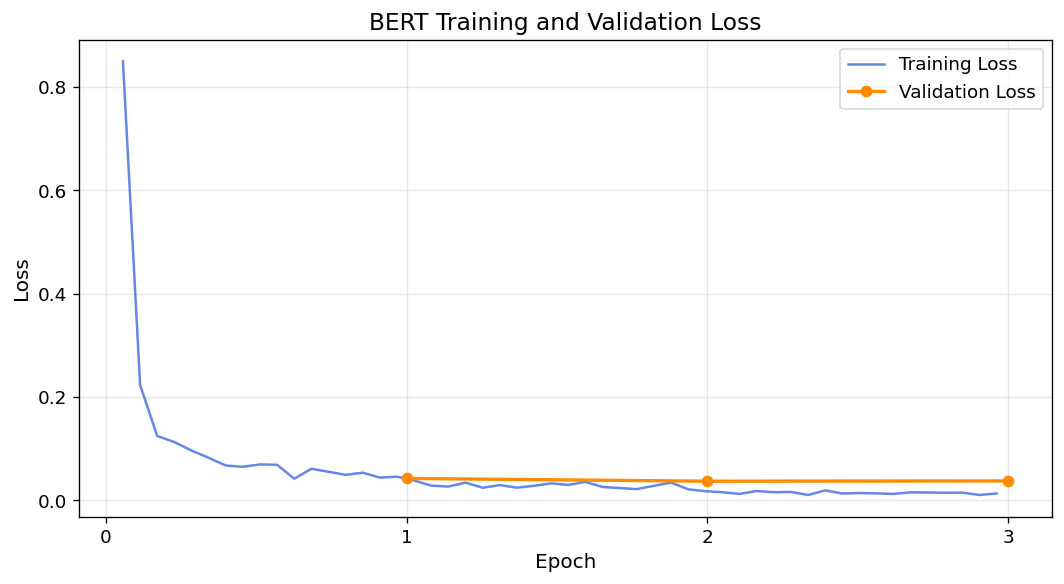

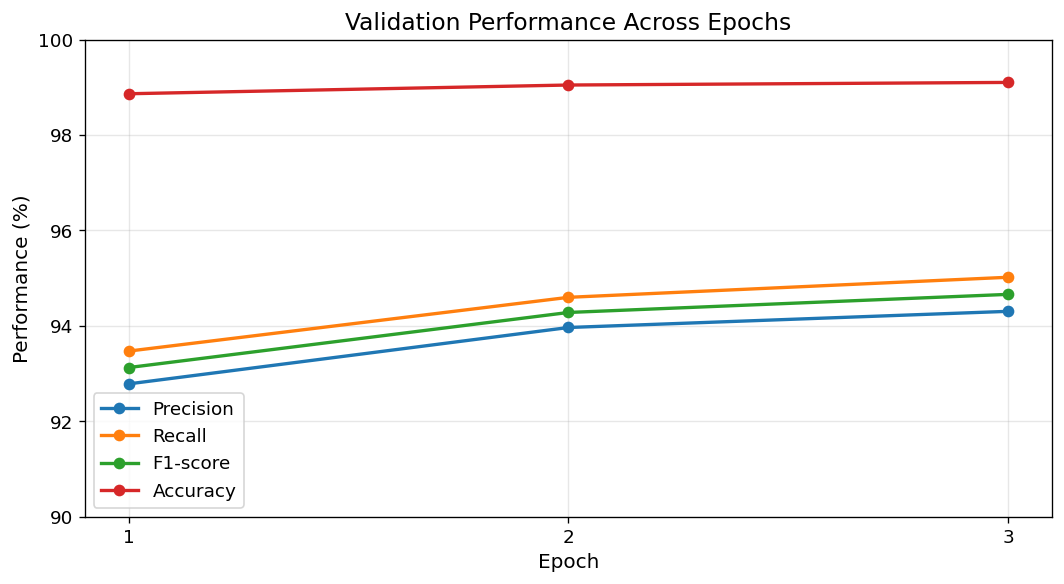

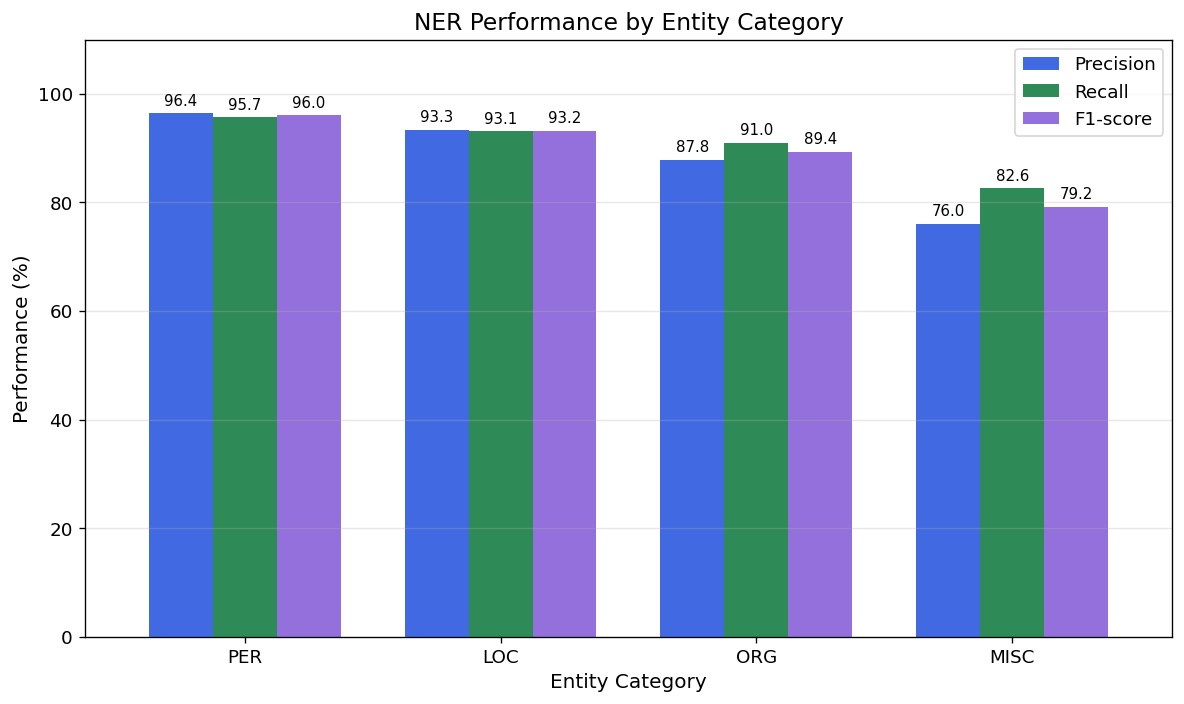

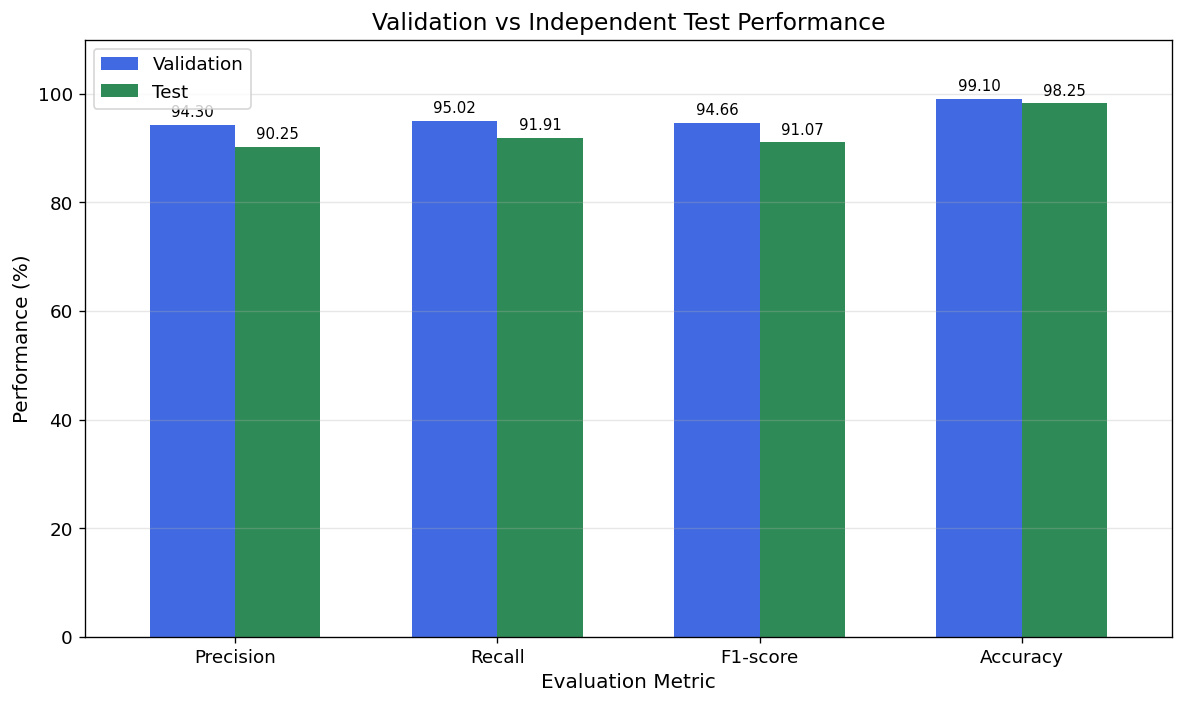


Performance visualisation completed successfully!
Results directory: /content/drive/MyDrive/AIROST_NER/evaluation_results

Saved files:
- entity_classification_report.csv
- entity_performance.png
- evaluation_summary.json
- training_history.csv
- training_validation_loss.png
- validation_metrics.png
- validation_test_comparison.png


In [66]:
# Model Performance Visualisation
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np
import json

# Create persistent evaluation results directory
results_dir = project_drive_dir / "evaluation_results"

results_dir.mkdir(
    parents=True,
    exist_ok=True
)

# Retrieve actual training history from saved checkpoint
training_history = pd.DataFrame(
    saved_state["log_history"]
)

# Extract validation records
validation_history = training_history[
    training_history["eval_f1"].notna()
].copy()

# Retrieve training loss records
loss_history = training_history[
    training_history["loss"].notna()
].copy()

# Configure graph appearance
plt.rcParams.update({
    "figure.dpi": 120,
    "font.size": 11,
    "axes.titlesize": 14,
    "axes.labelsize": 12
})

# Figure 1: Training and Validation Loss
plt.figure(figsize=(9, 5))

plt.plot(
    loss_history["epoch"],
    loss_history["loss"],
    color="royalblue",
    alpha=0.8,
    label="Training Loss"
)

plt.plot(
    validation_history["epoch"],
    validation_history["eval_loss"],
    marker="o",
    color="darkorange",
    linewidth=2,
    label="Validation Loss"
)

plt.title("BERT Training and Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.xticks([0, 1, 2, 3])
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig(
    results_dir / "training_validation_loss.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close()

# Figure 2: Validation Metrics
plt.figure(figsize=(9, 5))

metrics = {
    "eval_precision": "Precision",
    "eval_recall": "Recall",
    "eval_f1": "F1-score",
    "eval_accuracy": "Accuracy"
}

for column, name in metrics.items():

    plt.plot(
        validation_history["epoch"],
        validation_history[column] * 100,
        marker="o",
        linewidth=2,
        label=name
    )

plt.title("Validation Performance Across Epochs")
plt.xlabel("Epoch")
plt.ylabel("Performance (%)")
plt.xticks([1, 2, 3])
plt.ylim(90, 100)
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig(
    results_dir / "validation_metrics.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close()

# Figure 3: Individual Entity Performance
entity_plot = entity_results[
    ["precision", "recall", "f1-score"]
] * 100

ax = entity_plot.plot(
    kind="bar",
    figsize=(10, 6),
    color=["royalblue", "seagreen", "mediumpurple"],
    width=0.75
)

plt.title("NER Performance by Entity Category")
plt.xlabel("Entity Category")
plt.ylabel("Performance (%)")
plt.xticks(rotation=0)
plt.ylim(0, 110)
plt.legend(["Precision", "Recall", "F1-score"])
plt.grid(axis="y", alpha=0.3)

for container in ax.containers:
    ax.bar_label(
        container,
        fmt="%.1f",
        fontsize=9,
        padding=3
    )

plt.tight_layout()

plt.savefig(
    results_dir / "entity_performance.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close()

# Figure 4: Validation vs Test Performance
comparison = pd.DataFrame({
    "Validation": [
        verification_results["eval_precision"],
        verification_results["eval_recall"],
        verification_results["eval_f1"],
        verification_results["eval_accuracy"]
    ],
    "Test": [
        test_results["test_precision"],
        test_results["test_recall"],
        test_results["test_f1"],
        test_results["test_accuracy"]
    ]
}, index=[
    "Precision",
    "Recall",
    "F1-score",
    "Accuracy"
]) * 100

ax = comparison.plot(
    kind="bar",
    figsize=(10, 6),
    color=["royalblue", "seagreen"],
    width=0.65
)

plt.title("Validation vs Independent Test Performance")
plt.xlabel("Evaluation Metric")
plt.ylabel("Performance (%)")
plt.xticks(rotation=0)
plt.ylim(0, 110)
plt.legend()
plt.grid(axis="y", alpha=0.3)

for container in ax.containers:
    ax.bar_label(
        container,
        fmt="%.2f",
        fontsize=9,
        padding=3
    )

plt.tight_layout()

plt.savefig(
    results_dir / "validation_test_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close()

# Save numerical evaluation results
entity_results.to_csv(
    results_dir / "entity_classification_report.csv"
)

training_history.to_csv(
    results_dir / "training_history.csv",
    index=False
)

evaluation_summary = {
    "checkpoint": str(best_checkpoint_dir),
    "original_validation_f1": float(original_f1),
    "validation_results": verification_results,
    "test_results": test_results,
    "airost_required_categories": {
        "precision": float(
            required_results["overall_precision"]
        ),
        "recall": float(
            required_results["overall_recall"]
        ),
        "f1": float(
            required_results["overall_f1"]
        )
    }
}

with open(
    results_dir / "evaluation_summary.json",
    "w",
    encoding="utf-8"
) as file:

    json.dump(
        evaluation_summary,
        file,
        indent=4
    )

# Verify saved results
print("\nPerformance visualisation completed successfully!")
print("Results directory:", results_dir)

print("\nSaved files:")

for file in sorted(results_dir.iterdir()):
    print(f"- {file.name}")

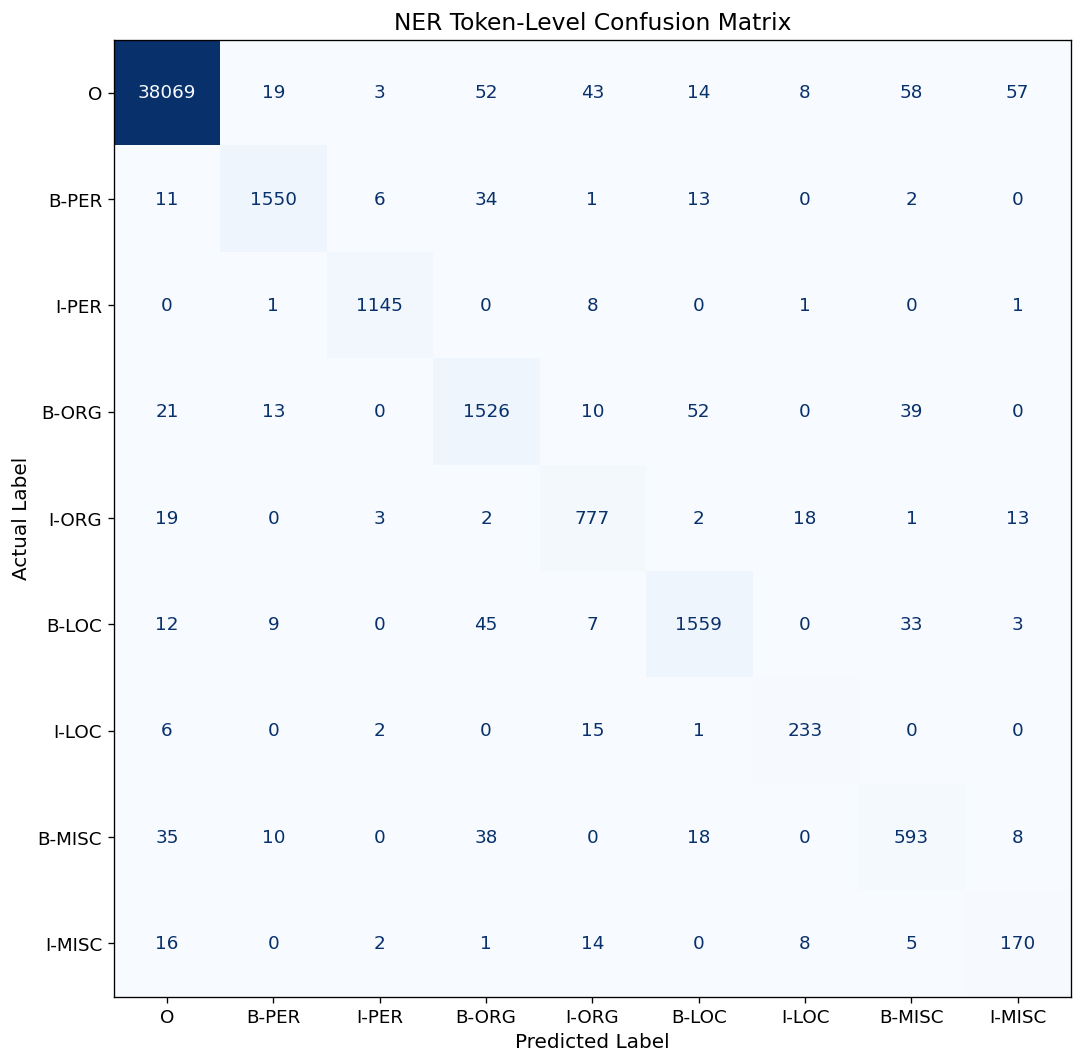

Prediction Error Analysis
------------------------------------
Total evaluated words: 46435
Incorrect word predictions: 813
Correct word predictions: 45622
Word-level error rate: 1.75%

Error Type Summary:


,error_type,count
0,Wrong entity category,406
1,False positive token,254
2,Missed entity token,120
3,BIO boundary label error,33



Sample Prediction Errors:


,word,actual_label,predicted_label,error_type,sentence
0,JAPAN,B-LOC,B-PER,Wrong entity category,"SOCCER - JAPAN GET LUCKY WIN , CHINA IN SURPRI..."
1,LUCKY,O,B-PER,False positive token,"SOCCER - JAPAN GET LUCKY WIN , CHINA IN SURPRI..."
2,CHINA,B-PER,B-ORG,Wrong entity category,"SOCCER - JAPAN GET LUCKY WIN , CHINA IN SURPRI..."
3,C,O,I-MISC,False positive token,Japan began the defence of their Asian Cup tit...
4,Bitar,B-PER,B-ORG,Wrong entity category,Defender Hassan Abbas rose to intercept a long...
5,Bitar,B-PER,B-ORG,Wrong entity category,Bitar pulled off fine saves whenever they did .
6,CUTTITTA,B-PER,B-ORG,Wrong entity category,RUGBY UNION - CUTTITTA BACK FOR ITALY AFTER A ...
7,ITALY,B-LOC,B-ORG,Wrong entity category,RUGBY UNION - CUTTITTA BACK FOR ITALY AFTER A ...
8,1995,B-MISC,O,Missed entity token,Cuttitta announced his retirement after the 19...
9,World,I-MISC,B-MISC,BIO boundary label error,Cuttitta announced his retirement after the 19...



Sample Organisation-Related Errors:


,word,actual_label,predicted_label,error_type,sentence
2,CHINA,B-PER,B-ORG,Wrong entity category,"SOCCER - JAPAN GET LUCKY WIN , CHINA IN SURPRI..."
4,Bitar,B-PER,B-ORG,Wrong entity category,Defender Hassan Abbas rose to intercept a long...
5,Bitar,B-PER,B-ORG,Wrong entity category,Bitar pulled off fine saves whenever they did .
6,CUTTITTA,B-PER,B-ORG,Wrong entity category,RUGBY UNION - CUTTITTA BACK FOR ITALY AFTER A ...
7,ITALY,B-LOC,B-ORG,Wrong entity category,RUGBY UNION - CUTTITTA BACK FOR ITALY AFTER A ...
11,Bitar,B-PER,B-ORG,Wrong entity category,Defender Hassan Abbas rose to intercept a long...
13,Astle,B-PER,B-ORG,Wrong entity category,Astle 9-0-53-1 ( w-1 nb-1 )
16,Engllsh,B-MISC,B-ORG,Wrong entity category,"Blinker was fined 75,000 Swiss francs ( $ 57,6..."
17,LEEDS,B-ORG,O,Missed entity token,SOCCER - LEEDS ' BOWYER FINED FOR PART IN FAST...
18,Villeurbanne,B-ORG,B-PER,Wrong entity category,Villeurbanne ( France ) 9 6 3 15



Prediction error analysis completed successfully!

Saved files:
- confusion_matrix.png
- confusion_matrix.csv
- prediction_errors.csv
- error_type_summary.csv


In [67]:
# Prediction Error Analysis
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics import confusion_matrix
from sklearn.metrics import ConfusionMatrixDisplay

# 1. Prepare word-level evaluation data
flat_true_labels = [
    tag
    for sequence in true_labels
    for tag in sequence
]

flat_predicted_labels = [
    tag
    for sequence in true_predictions
    for tag in sequence
]

assert len(flat_true_labels) == len(flat_predicted_labels)

# 2. Generate confusion matrix
cm = confusion_matrix(
    flat_true_labels,
    flat_predicted_labels,
    labels=label_names
)

fig, ax = plt.subplots(figsize=(11, 9))

ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=label_names
).plot(
    ax=ax,
    cmap="Blues",
    values_format="d",
    colorbar=False
)

plt.title("NER Token-Level Confusion Matrix")
plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.tight_layout()

plt.savefig(
    results_dir / "confusion_matrix.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close()

# Save confusion matrix as CSV
cm_df = pd.DataFrame(
    cm,
    index=label_names,
    columns=label_names
)

cm_df.to_csv(
    results_dir / "confusion_matrix.csv"
)

# 3. Identify incorrect predictions
error_records = []

for sentence_id, (actual_tags, predicted_tags) in enumerate(
    zip(true_labels, true_predictions)
):

    words = dataset["test"][sentence_id]["tokens"]

    # Check word-label alignment
    if len(words) != len(actual_tags):
        raise ValueError(
            f"Word-label mismatch in sentence {sentence_id}"
        )

    for word_id, (word, actual, predicted) in enumerate(
        zip(words, actual_tags, predicted_tags)
    ):

        if actual != predicted:

            # Categorise the token-level error
            if actual != "O" and predicted == "O":
                error_type = "Missed entity token"

            elif actual == "O" and predicted != "O":
                error_type = "False positive token"

            elif actual.split("-")[-1] != predicted.split("-")[-1]:
                error_type = "Wrong entity category"

            else:
                error_type = "BIO boundary label error"

            error_records.append({
                "sentence_id": sentence_id,
                "word_id": word_id,
                "word": word,
                "actual_label": actual,
                "predicted_label": predicted,
                "error_type": error_type,
                "sentence": " ".join(words)
            })

# Create error analysis table
error_df = pd.DataFrame(error_records)

# 4. Display error statistics
total_words = len(flat_true_labels)
total_errors = len(error_df)

print("Prediction Error Analysis")
print("------------------------------------")

print("Total evaluated words:", total_words)
print("Incorrect word predictions:", total_errors)
print("Correct word predictions:",
      total_words - total_errors)

print(f"Word-level error rate: "
      f"{total_errors / total_words * 100:.2f}%")

# Count errors by type
error_summary = (
    error_df["error_type"]
    .value_counts()
    .rename_axis("error_type")
    .reset_index(name="count")
)

print("\nError Type Summary:")
display(error_summary)

# 5. Display actual prediction errors
print("\nSample Prediction Errors:")

display(
    error_df[
        [
            "word",
            "actual_label",
            "predicted_label",
            "error_type",
            "sentence"
        ]
    ].head(10)
)

# Display organisation-related errors
org_errors = error_df[
    error_df["actual_label"].str.endswith("-ORG") |
    error_df["predicted_label"].str.endswith("-ORG")
]

print("\nSample Organisation-Related Errors:")

display(
    org_errors[
        [
            "word",
            "actual_label",
            "predicted_label",
            "error_type",
            "sentence"
        ]
    ].head(10)
)

# 6. Save error analysis results
error_df.to_csv(
    results_dir / "prediction_errors.csv",
    index=False
)

error_summary.to_csv(
    results_dir / "error_type_summary.csv",
    index=False
)

print("\nPrediction error analysis completed successfully!")

print("\nSaved files:")
print("- confusion_matrix.png")
print("- confusion_matrix.csv")
print("- prediction_errors.csv")
print("- error_type_summary.csv")

In [68]:
# Final Model and Tokenizer Export
from pathlib import Path
from transformers import AutoTokenizer
import json

# Ensure model performance verification has passed
assert f1_difference <= 0.001, \
    "Model verification must pass before export."

# Ensure the final model directory exists
final_model_dir = project_drive_dir / "final_model"

final_model_dir.mkdir(
    parents=True,
    exist_ok=True
)

print("Exporting the verified fine-tuned BERT model...")
print("Source checkpoint:", best_checkpoint_dir)
print("Destination:", final_model_dir)

# Load tokenizer directly from the selected checkpoint
final_tokenizer = AutoTokenizer.from_pretrained(
    str(best_checkpoint_dir),
    local_files_only=True
)

# Save the verified fine-tuned model
verified_model.save_pretrained(
    str(final_model_dir)
)

# Save the corresponding tokenizer
final_tokenizer.save_pretrained(
    str(final_model_dir)
)

# Save model evaluation information
model_information = {
    "base_model": "bert-base-cased",
    "model_type": verified_model.config.model_type,
    "number_of_labels": verified_model.config.num_labels,
    "parameter_count": verified_model.num_parameters(),
    "label_mapping": verified_model.config.id2label,
    "selected_checkpoint": best_checkpoint_dir.name,
    "training_epochs": saved_state["epoch"],
    "training_steps": saved_state["global_step"],
    "validation_f1": float(reloaded_f1),
    "test_precision": float(test_results["test_precision"]),
    "test_recall": float(test_results["test_recall"]),
    "test_f1": float(test_results["test_f1"]),
    "test_accuracy": float(test_results["test_accuracy"]),
    "required_categories": ["PER", "LOC", "ORG"],
    "required_categories_precision": float(
        required_results["overall_precision"]
    ),
    "required_categories_recall": float(
        required_results["overall_recall"]
    ),
    "required_categories_f1": float(
        required_results["overall_f1"]
    )
}

with open(
    final_model_dir / "model_information.json",
    "w",
    encoding="utf-8"
) as file:

    json.dump(
        model_information,
        file,
        indent=4
    )

# Verify essential exported files
required_files = [
    "model.safetensors",
    "config.json",
    "tokenizer.json",
    "tokenizer_config.json",
    "model_information.json"
]

print("\nExported File Verification")
print("------------------------------------")

for filename in required_files:

    file_path = final_model_dir / filename

    print(f"{filename}: {file_path.is_file()}")

assert all(
    (final_model_dir / filename).is_file()
    for filename in required_files
), "Some required model files are missing."

# Calculate actual exported model size
total_size = 0

print("\nExported Files and Sizes")
print("------------------------------------")

for file in sorted(final_model_dir.iterdir()):

    if file.is_file():

        file_size = file.stat().st_size
        total_size += file_size

        print(
            f"{file.name}: "
            f"{file_size / (1024 ** 2):.2f} MB"
        )

print(f"\nTotal model size: "
      f"{total_size / (1024 ** 2):.2f} MB")

print("Final model directory:", final_model_dir)

print("\nFinal model and tokenizer exported successfully!")


Exporting the verified fine-tuned BERT model...
Source checkpoint: /content/drive/MyDrive/AIROST_NER/checkpoints/checkpoint-2634
Destination: /content/drive/MyDrive/AIROST_NER/final_model


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]


Exported File Verification
------------------------------------
model.safetensors: True
config.json: True
tokenizer.json: True
tokenizer_config.json: True
model_information.json: True

Exported Files and Sizes
------------------------------------
config.json: 0.00 MB
model.safetensors: 410.97 MB
model_information.json: 0.00 MB
tokenizer.json: 0.64 MB
tokenizer_config.json: 0.00 MB

Total model size: 411.61 MB
Final model directory: /content/drive/MyDrive/AIROST_NER/final_model

Final model and tokenizer exported successfully!
